I0000 00:00:1794639549.705152    1236 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794639550.537793    1236 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794639553.210715    1236 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1794639555.062765    1323 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO

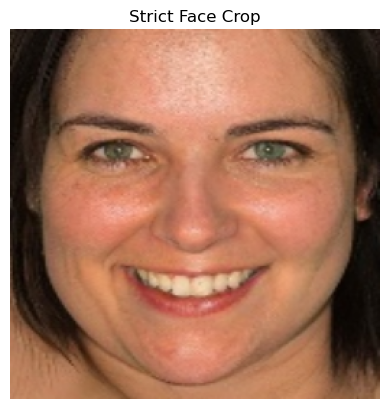

In [1]:
import os
import cv2
import numpy as np
import mediapipe as mp
import matplotlib.pyplot as plt

# Initialize MediaPipe Face Landmarker
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

base_options = python.BaseOptions(model_asset_path="face_landmarker.task")
options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    num_faces=1,
    min_face_detection_confidence=0.5,
    min_face_presence_confidence=0.5,
    min_tracking_confidence=0.5
)
landmarker = vision.FaceLandmarker.create_from_options(options)

def extract_and_crop_face(image_path, padding=10):
    """
    Reads an image, detects the face, and returns a cropped 
    RGB face image to prevent background data leakage.
    """
    image = cv2.imread(image_path)
    if image is None:
        return None
        
    # Convert BGR to RGB for MediaPipe and Matplotlib
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_image)
    
    # Detect landmarks
    result = landmarker.detect(mp_image)
    
    # If no face is detected, return None
    if not result.face_landmarks:
        return None

    landmarks = result.face_landmarks[0]
    h, w, _ = rgb_image.shape
    
    # Extract X and Y coordinates
    xs = np.array([p.x for p in landmarks])
    ys = np.array([p.y for p in landmarks])
    
    # Convert normalized coordinates to actual pixel values
    x_min, x_max = int(xs.min() * w), int(xs.max() * w)
    y_min, y_max = int(ys.min() * h), int(ys.max() * h)
    
    # Apply padding while ensuring we don't go outside image boundaries
    x_min = max(0, x_min - padding)
    x_max = min(w, x_max + padding)
    y_min = max(0, y_min - padding)
    y_max = min(h, y_max + padding)
    
    # Crop the face
    face_crop = rgb_image[y_min:y_max, x_min:x_max]
    
    # Resize to standard 256x256 for consistent feature extraction later
    face_crop_resized = cv2.resize(face_crop, (256, 256))
    
    return face_crop_resized

# Test the function with a sample image

test_image_path = "/mnt/d/ImageProcessing_Dataset/test/03.jpg" 

cropped_face = extract_and_crop_face(test_image_path)

if cropped_face is not None:
    plt.imshow(cropped_face)
    plt.title("Strict Face Crop")
    plt.axis("off")
    plt.show()
else:
    print("No face detected in the test image.")

In [2]:
from skimage.feature import local_binary_pattern, hog

# 1. Texture Feature: Local Binary Pattern (LBP) - Detects synthetic skin textures
def extract_lbp(gray_image):
    lbp = local_binary_pattern(gray_image, P=8, R=1, method="uniform")
    histogram, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), range=(0, 10))
    histogram = histogram.astype("float32")
    return histogram / (histogram.sum() + 1e-7)

# 2. Structural Feature: Edge Maps - Detects blending boundaries and blur
def extract_edge_features(gray_image):
    edges = cv2.Canny(gray_image, 100, 200)
    sobel_x = cv2.Sobel(gray_image, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray_image, cv2.CV_64F, 0, 1, ksize=3)
    return np.array([
        np.mean(edges > 0), 
        np.mean(np.abs(sobel_x)), 
        np.mean(np.abs(sobel_y)), 
        np.mean(np.sqrt(sobel_x**2 + sobel_y**2))
    ], dtype=np.float32)

# 3. Frequency Feature: FFT Radial Profile - Detects GAN upsampling noise
def extract_fft_radial(gray_image):
    f = np.fft.fft2(gray_image)
    fshift = np.fft.fftshift(f)
    magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1e-7)
    h, w = magnitude_spectrum.shape
    cy, cx = h // 2, w // 2
    y, x = np.ogrid[-cy:h-cy, -cx:w-cx]
    r = np.sqrt(x*x + y*y).astype(int)
    radial_profile = np.bincount(r.ravel(), weights=magnitude_spectrum.ravel())
    radial_profile /= (np.bincount(r.ravel()) + 1e-7)
    return radial_profile[:32].astype(np.float32)

# 4. Shape Feature: HOG - Detects structural gradients
def extract_optimized_hog(gray_image):
    return hog(gray_image, orientations=8, pixels_per_cell=(32, 32), cells_per_block=(2, 2), visualize=False).astype(np.float32)

# 5. Make a master function to extract all features from the strictly cropped face
def master_extract_features(image_path):
    # Step A: Get the strict face crop using the function we built in Step 1
    face_crop_rgb = extract_and_crop_face(image_path)
    
    if face_crop_rgb is None:
        return None # skip images where no face is found
        
    # Step B: Convert strictly cropped face to grayscale
    gray_face = cv2.cvtColor(face_crop_rgb, cv2.COLOR_RGB2GRAY)
    
    # Step C: Extract anomaly signals ONLY from the facial pixels
    features = np.concatenate([
        extract_lbp(gray_face),            # Micro-textures (10 features)
        extract_edge_features(gray_face),  # Blending boundaries (4 features)
        extract_fft_radial(gray_face),     # GAN frequencies (32 features)
        extract_optimized_hog(gray_face)   # Structural gradients (~1152 features)
    ])
    
    return features

# Test the master feature extraction function with a sample image
# We will use the same test_image_path from Step 1
test_features = master_extract_features(test_image_path)

if test_features is not None:
    print(f"Success! Extracted a 1D feature array of length {len(test_features)} strictly from the facial region.")
else:
    print("Failed to extract features.")

Success! Extracted a 1D feature array of length 1614 strictly from the facial region.


In [3]:
import time

def create_dataset(split, max_images_per_class):
    data = []
    
    split_path = os.path.join("/mnt/d/ImageProcessing_Dataset/archive/real_vs_fake/real-vs-fake", split)
    
    classes = {"real": 0, "fake": 1}

    for class_name, label in classes.items():
        class_path = os.path.join(split_path, class_name)
        if not os.path.exists(class_path):
            print(f"Warning: Directory missing -> {class_path}")
            continue

        files = [f for f in os.listdir(class_path) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        files = files[:max_images_per_class]
        
        print(f"Processing Split: '{split.upper()}' | Category: '{class_name.upper()}' | {len(files)} items...")

        for filename in files:
            image_path = os.path.join(class_path, filename)
            
            # Use our new strict face-only extraction pipeline
            features = master_extract_features(image_path)
            
            if features is not None:
                # Append label to the end of the feature array
                row = np.append(features, label)
                data.append(row)

    return np.array(data, dtype=np.float32)

print("Starting dataset compilation on a fast subset...")
start_time = time.time()

# 1. Compile the Data 
train_data = create_dataset("train", max_images_per_class=1500)  # 3000 total
val_data = create_dataset("valid", max_images_per_class=500)    # 1000 total
test_data = create_dataset("test", max_images_per_class=500)    # 1000 total

print(f"\nExtraction Complete in {(time.time() - start_time):.2f} seconds!")
print(f"Train dimensions: {train_data.shape}")
print(f"Validation dimensions: {val_data.shape}")
print(f"Test dimensions: {test_data.shape}")

# 2. Serialize safely to disk
np.savez_compressed("artifact_only_features_subset.npz", train=train_data, val=val_data, test=test_data)
print("New subset dataset successfully saved as 'artifact_only_features_subset.npz'.")

Starting dataset compilation on a fast subset...
Processing Split: 'TRAIN' | Category: 'REAL' | 1500 items...
Processing Split: 'TRAIN' | Category: 'FAKE' | 1500 items...
Processing Split: 'VALID' | Category: 'REAL' | 500 items...
Processing Split: 'VALID' | Category: 'FAKE' | 500 items...
Processing Split: 'TEST' | Category: 'REAL' | 500 items...
Processing Split: 'TEST' | Category: 'FAKE' | 500 items...

Extraction Complete in 216.24 seconds!
Train dimensions: (3000, 1615)
Validation dimensions: (998, 1615)
Test dimensions: (998, 1615)
New subset dataset successfully saved as 'artifact_only_features_subset.npz'.


In [4]:
import numpy as np
import joblib
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# 1. Load the clean, cropped features from disk
loaded_dataset = np.load("artifact_only_features_subset.npz")
train_data = loaded_dataset["train"]
val_data = loaded_dataset["val"]
test_data = loaded_dataset["test"]

# 2. Separate features (X) and target labels (y)
X_train, y_train = train_data[:, :-1], train_data[:, -1]
X_val, y_val = val_data[:, :-1], val_data[:, -1]
X_test, y_test = test_data[:, :-1], test_data[:, -1]

# 3. Fit the scaler ONLY on the training data to prevent data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 4. Train a highly regularized XGBoost Ensemble
# max_depth=4 prevents the model from building overly complex rules (prevents overfitting)
print("Training Extreme Gradient Boosting Ensemble Model on facial artifacts...")
model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)
model.fit(X_train_scaled, y_train)

# 5. Evaluate Performance on the Validation and Test splits
val_predictions = model.predict(X_val_scaled)
test_predictions = model.predict(X_test_scaled)

print("\n--- XGBoost Test Metrics Report ---")
print(f"Validation Accuracy: {accuracy_score(y_val, val_predictions):.4f}")
print(f"Test Accuracy:       {accuracy_score(y_test, test_predictions):.4f}")
print("\nClassification Report (Test Set):")
print(classification_report(y_test, test_predictions, target_names=["Real", "Fake"]))

# 6. Save the trained pipeline
joblib.dump(model, 'real_fake_xgboost_clean.pkl')
joblib.dump(scaler, 'feature_scaler_clean.pkl')
print("\nClean XGBoost pipeline files serialized successfully!")

Training Extreme Gradient Boosting Ensemble Model on facial artifacts...

--- XGBoost Test Metrics Report ---
Validation Accuracy: 0.7745
Test Accuracy:       0.7585

Classification Report (Test Set):
              precision    recall  f1-score   support

        Real       0.76      0.75      0.76       498
        Fake       0.75      0.77      0.76       500

    accuracy                           0.76       998
   macro avg       0.76      0.76      0.76       998
weighted avg       0.76      0.76      0.76       998


Clean XGBoost pipeline files serialized successfully!


Extracting features from facial pixels...


/home/rahul/miniconda3/envs/tf/lib/python3.10/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


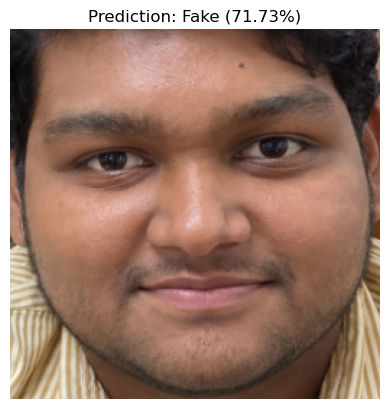


 Target Source: fake03.png
 Prediction: [ FAKE ]
 Confidence: 71.73%
 Distribution -> Real: 0.2827 | Fake: 0.7173



In [5]:
import cv2
import numpy as np
import pandas as pd
import joblib
import os
import matplotlib.pyplot as plt

# We are using the master_extract_features and extract_and_crop_face 
# functions you already defined in memory from Step 1 and Step 2.

def predict_real_world_image(image_path, model_path='real_fake_xgboost_clean.pkl', scaler_path='feature_scaler_clean.pkl'):
    # 1. Path Validation
    if not os.path.exists(image_path):
        print(f"Error: Target image file not found at -> {image_path}")
        return
        
    if not os.path.exists(model_path) or not os.path.exists(scaler_path):
        print("Error: Trained model weights (.pkl) or scaler files are missing.")
        return

    # 2. Extract strictly cropped facial features
    print("Extracting features from facial pixels...")
    features = master_extract_features(image_path)
    
    if features is None:
        print(f"Prediction Aborted: No valid human face tracked in -> {image_path}")
        return

    # 3. Reshape and bypass Scikit-Learn name checks
    features_reshaped = features.reshape(1, -1)
    feature_names = [f"feature_{i}" for i in range(features_reshaped.shape[1])]
    features_df = pd.DataFrame(features_reshaped, columns=feature_names)

    # 4. Load artifacts and predict
    loaded_model = joblib.load(model_path)
    loaded_scaler = joblib.load(scaler_path)
    
    features_scaled = loaded_scaler.transform(features_df)
    prediction_idx = int(loaded_model.predict(features_scaled)[0])
    probabilities = loaded_model.predict_proba(features_scaled)[0]

    class_label = "Fake" if prediction_idx == 1 else "Real"
    confidence_score = probabilities[prediction_idx] * 100

    # 5. Display what the model actually saw
    face_crop = extract_and_crop_face(image_path)
    plt.imshow(face_crop)
    plt.title(f"Prediction: {class_label} ({confidence_score:.2f}%)")
    plt.axis("off")
    plt.show()

    # 6. Print detailed terminal output
    print(f"\n==========================================")
    print(f" Target Source: {os.path.basename(image_path)}")
    print(f" Prediction: [ {class_label.upper()} ]")
    print(f" Confidence: {confidence_score:.2f}%")
    print(f" Distribution -> Real: {probabilities[0]:.4f} | Fake: {probabilities[1]:.4f}")
    print(f"==========================================\n")

# --- RUN THE REAL-WORLD TEST ---
# WARNING: Change this path to a random image you downloaded from the internet!
real_world_image_path = "/mnt/d/ImageProcessing_Dataset/test/fake03.png" 

predict_real_world_image(real_world_image_path)

Running predictions on the test set...


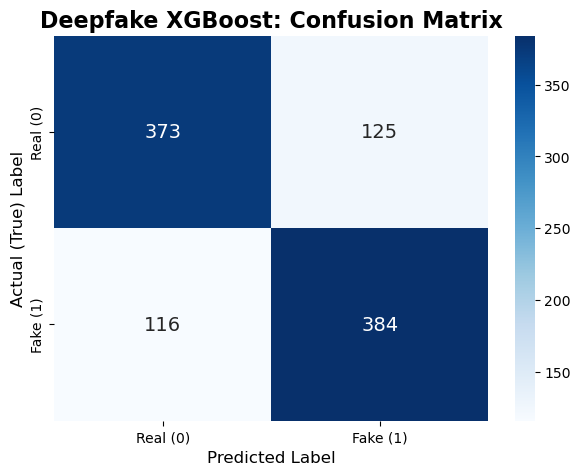

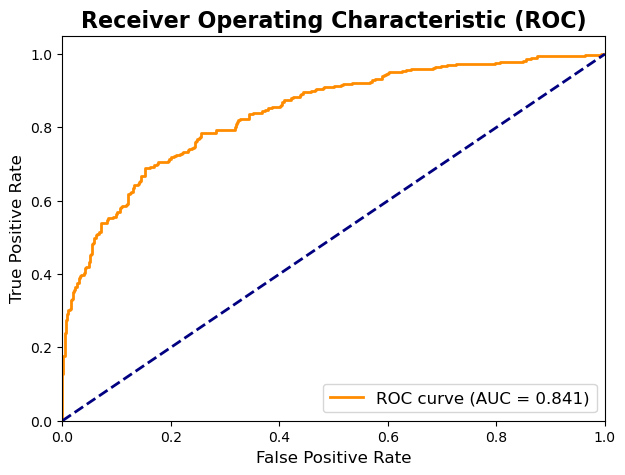

In [6]:
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# 1. Load the clean test data
loaded_dataset = np.load("artifact_only_features_subset.npz")
test_data = loaded_dataset["test"]
X_test, y_test = test_data[:, :-1], test_data[:, -1]

# 2. Load the trained XGBoost model and scaler
loaded_model = joblib.load('real_fake_xgboost_clean.pkl')
loaded_scaler = joblib.load('feature_scaler_clean.pkl')

# 3. Scale test features and predict
print("Running predictions on the test set...")
X_test_scaled = loaded_scaler.transform(X_test)
test_predictions = loaded_model.predict(X_test_scaled)
test_probabilities = loaded_model.predict_proba(X_test_scaled)[:, 1] # Get probabilities for the "Fake" class

# ==========================================
# GRAPH 1: CONFUSION MATRIX
# ==========================================
cm = confusion_matrix(y_test, test_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Real (0)', 'Fake (1)'], 
            yticklabels=['Real (0)', 'Fake (1)'],
            annot_kws={"size": 14}) # Larger font for the numbers

plt.title('Deepfake XGBoost: Confusion Matrix', fontsize=16, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual (True) Label', fontsize=12)
plt.show()

# ==========================================
# GRAPH 2: ROC CURVE
# ==========================================
fpr, tpr, thresholds = roc_curve(y_test, test_probabilities)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Diagonal 50/50 line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC)', fontsize=16, fontweight='bold')
plt.legend(loc="lower right", fontsize=12)
plt.show()